In [4]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set_theme(style="whitegrid", context="notebook")

In [19]:
df = pd.read_csv("../data/Cuisine_rating.csv")

# Clean column names
df.columns = df.columns.str.strip()

In [20]:
df.head()

,User ID,Area code,Location,Gender,YOB,Marital Status,Activity,Budget,Cuisines,Alcohol,Smoker,Food Rating,Service Rating,Overall Rating,Often A S
0,1,153,"Upper East Side,NY",Female,2006,Single,Professional,3,Japanese,Never,Never,5,4,4.5,No
1,2,123,"St. George,NY",Female,1991,Married,Student,3,Indian,Never,Socially,1,1,1.0,No
2,3,122,"Upper West Side,NY",Male,1977,Single,Student,5,Seafood,Often,Often,5,5,5.0,Yes
3,4,153,"Upper East Side,NY",Female,1956,Married,Professional,5,Japanese,Never,Socially,3,1,2.0,No
4,5,129,"Central Park,NY",Male,1997,Single,Student,4,Filipino,Socially,Never,2,4,3.0,No


In [21]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 200 entries, 0 to 199
Data columns (total 15 columns):
 #   Column          Non-Null Count  Dtype  
---  ------          --------------  -----  
 0   User ID         200 non-null    int64  
 1   Area code       200 non-null    int64  
 2   Location        200 non-null    str    
 3   Gender          200 non-null    str    
 4   YOB             200 non-null    int64  
 5   Marital Status  200 non-null    str    
 6   Activity        200 non-null    str    
 7   Budget          200 non-null    int64  
 8   Cuisines        200 non-null    str    
 9   Alcohol         200 non-null    str    
 10  Smoker          200 non-null    str    
 11  Food Rating     200 non-null    int64  
 12  Service Rating  200 non-null    int64  
 13  Overall Rating  200 non-null    float64
 14  Often A S       200 non-null    str    
dtypes: float64(1), int64(6), str(8)
memory usage: 23.6 KB


In [22]:
df.describe()

,User ID,Area code,YOB,Budget,Food Rating,Service Rating,Overall Rating
count,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000,200.000000
mean,100.500000,141.060000,1984.830000,3.815000,3.220000,3.230000,3.225000
std,57.879185,26.130257,16.809339,1.056578,1.411226,1.526022,1.079445
min,1.000000,101.000000,1955.000000,1.000000,1.000000,1.000000,1.000000
25%,50.750000,123.000000,1971.000000,3.000000,2.000000,2.000000,2.500000
50%,100.500000,135.000000,1987.000000,4.000000,3.000000,3.000000,3.000000
75%,150.250000,158.000000,2000.000000,5.000000,5.000000,5.000000,4.000000
max,200.000000,199.000000,2009.000000,5.000000,5.000000,5.000000,5.000000


In [23]:
df.describe(include="all")

,User ID,Area code,Location,Gender,YOB,Marital Status,Activity,Budget,Cuisines,Alcohol,Smoker,Food Rating,Service Rating,Overall Rating,Often A S
count,200.000000,200.000000,200,200,200.000000,200,200,200.000000,200,200,200,200.000000,200.000000,200.000000,200
unique,NaN,NaN,10,2,NaN,3,2,NaN,7,3,3,NaN,NaN,NaN,2
top,NaN,NaN,"St. George,NY",Male,NaN,Single,Student,NaN,Japanese,Never,Socially,NaN,NaN,NaN,No
freq,NaN,NaN,46,118,NaN,100,120,NaN,36,88,71,NaN,NaN,NaN,174
mean,100.500000,141.060000,NaN,NaN,1984.830000,NaN,NaN,3.815000,NaN,NaN,NaN,3.220000,3.230000,3.225000,NaN
std,57.879185,26.130257,NaN,NaN,16.809339,NaN,NaN,1.056578,NaN,NaN,NaN,1.411226,1.526022,1.079445,NaN
min,1.000000,101.000000,NaN,NaN,1955.000000,NaN,NaN,1.000000,NaN,NaN,NaN,1.000000,1.000000,1.000000,NaN
25%,50.750000,123.000000,NaN,NaN,1971.000000,NaN,NaN,3.000000,NaN,NaN,NaN,2.000000,2.000000,2.500000,NaN
50%,100.500000,135.000000,NaN,NaN,1987.000000,NaN,NaN,4.000000,NaN,NaN,NaN,3.000000,3.000000,3.000000,NaN
75%,150.250000,158.000000,NaN,NaN,2000.000000,NaN,NaN,5.000000,NaN,NaN,NaN,5.000000,5.000000,4.000000,NaN


In [24]:
df["Gender"].value_counts()

Gender
Male      118
Female     82
Name: count, dtype: int64

In [25]:
df["Cuisines"].value_counts()

Cuisines
Japanese    36
Filipino    34
French      34
Indian      32
Chinese     24
Seafood     22
Italian     18
Name: count, dtype: int64

In [26]:
from datetime import datetime
df["Age"] = datetime.now().year - df["YOB"]

df["Rating Category"] = pd.cut(
    df["Overall Rating"],
    bins=[0, 2, 3.5, 5],
    labels=["Low", "Medium", "High"],
    include_lowest=True
)

In [27]:
df["Rating Category"].value_counts(dropna=False)

Rating Category
Medium    101
High       61
Low        38
Name: count, dtype: int64

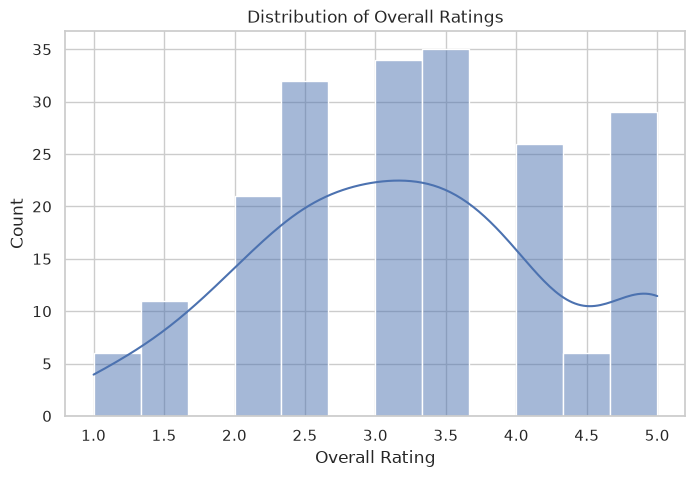

In [28]:
plt.figure(figsize=(8,5))
sns.histplot(df["Overall Rating"], bins=12, kde=True)
plt.title("Distribution of Overall Ratings")
plt.xlabel("Overall Rating")
plt.ylabel("Count")
plt.show()

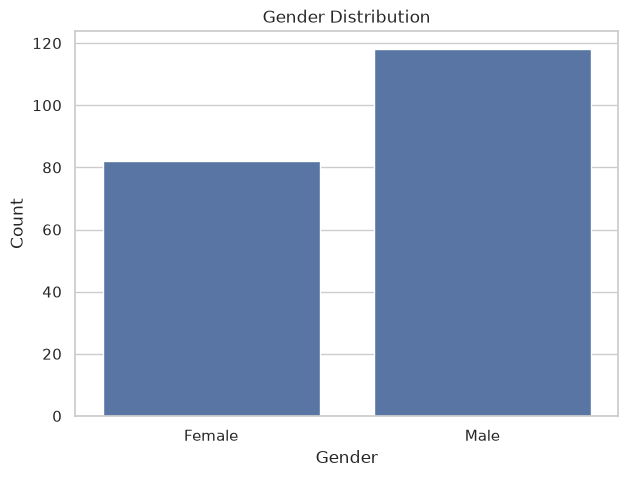

In [29]:
plt.figure(figsize=(7,5))
sns.countplot(x="Gender", data=df)
plt.title("Gender Distribution")
plt.xlabel("Gender")
plt.ylabel("Count")
plt.show()

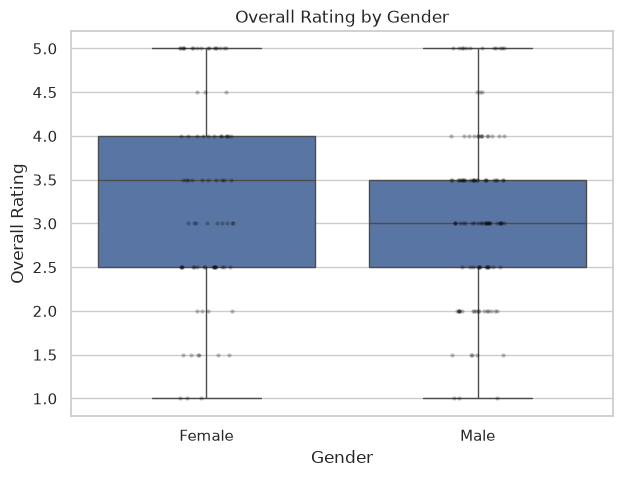

In [30]:
plt.figure(figsize=(7,5))
sns.boxplot(x="Gender", y="Overall Rating", data=df)
sns.stripplot(x="Gender", y="Overall Rating", data=df, color="black", alpha=0.25, size=3)
plt.title("Overall Rating by Gender")
plt.xlabel("Gender")
plt.ylabel("Overall Rating")
plt.show()

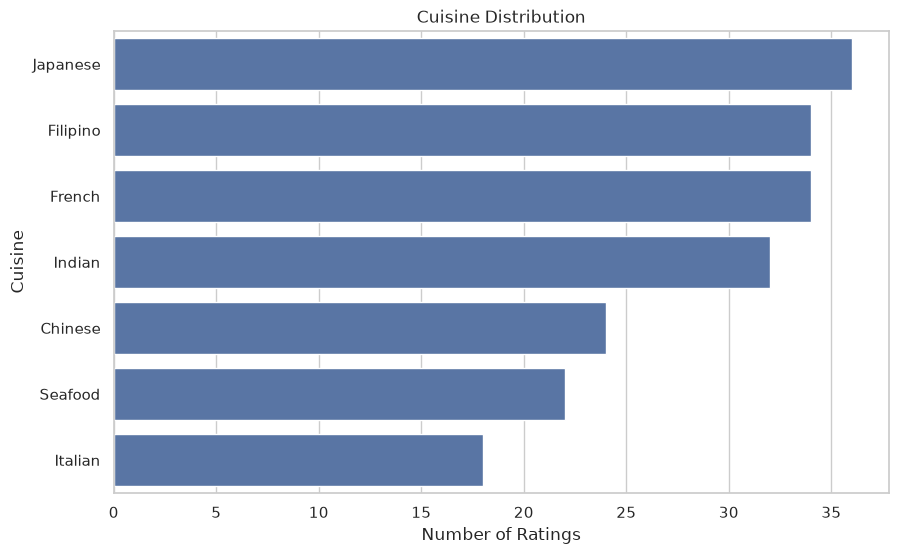

In [31]:
plt.figure(figsize=(10,6))
sns.countplot(
    y="Cuisines",
    data=df,
    order=df["Cuisines"].value_counts().index
)
plt.title("Cuisine Distribution")
plt.xlabel("Number of Ratings")
plt.ylabel("Cuisine")
plt.show()

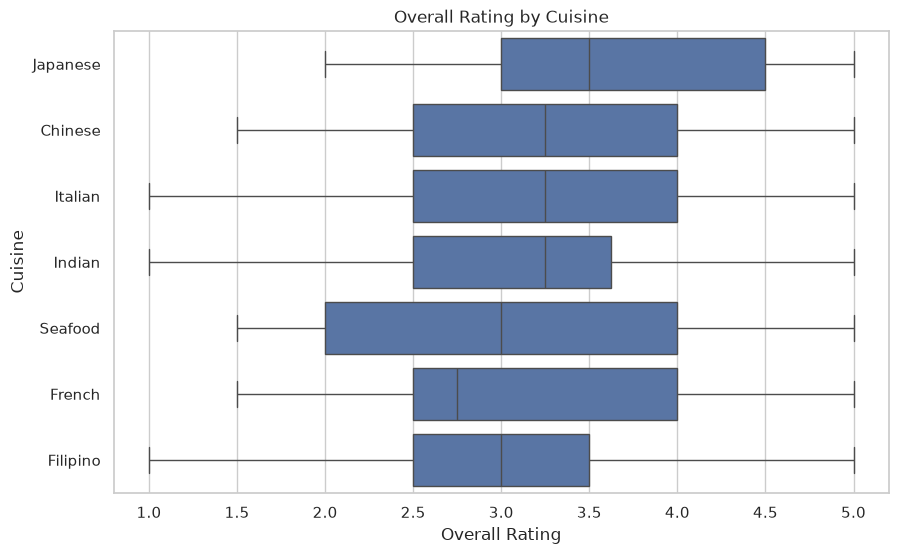

In [32]:
plt.figure(figsize=(10,6))
sns.boxplot(
    x="Overall Rating",
    y="Cuisines",
    data=df,
    order=df.groupby("Cuisines")["Overall Rating"]
            .mean()
            .sort_values(ascending=False)
            .index
)
plt.title("Overall Rating by Cuisine")
plt.xlabel("Overall Rating")
plt.ylabel("Cuisine")
plt.show()

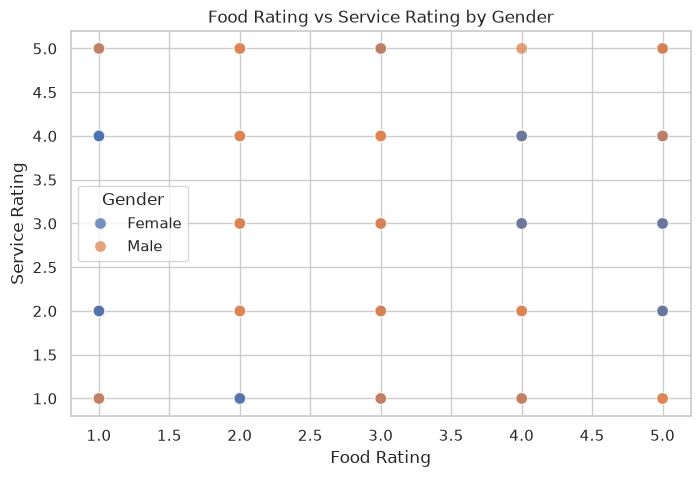

In [33]:
plt.figure(figsize=(8,5))
sns.scatterplot(
    x="Food Rating",
    y="Service Rating",
    hue="Gender",
    data=df,
    s=70,
    alpha=0.75
)
plt.title("Food Rating vs Service Rating by Gender")
plt.xlabel("Food Rating")
plt.ylabel("Service Rating")
plt.legend(title="Gender")
plt.show()

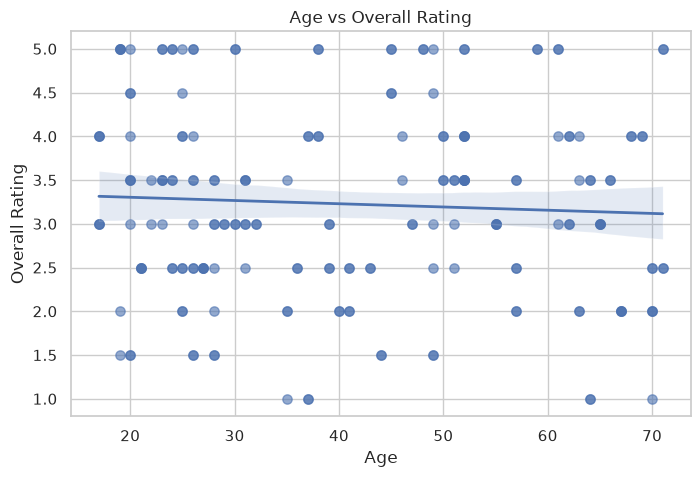

In [34]:
plt.figure(figsize=(8,5))
sns.regplot(
    x="Age",
    y="Overall Rating",
    data=df,
    scatter_kws={"alpha":0.6, "s":45},
    line_kws={"linewidth":2}
)
plt.title("Age vs Overall Rating")
plt.xlabel("Age")
plt.ylabel("Overall Rating")
plt.show()

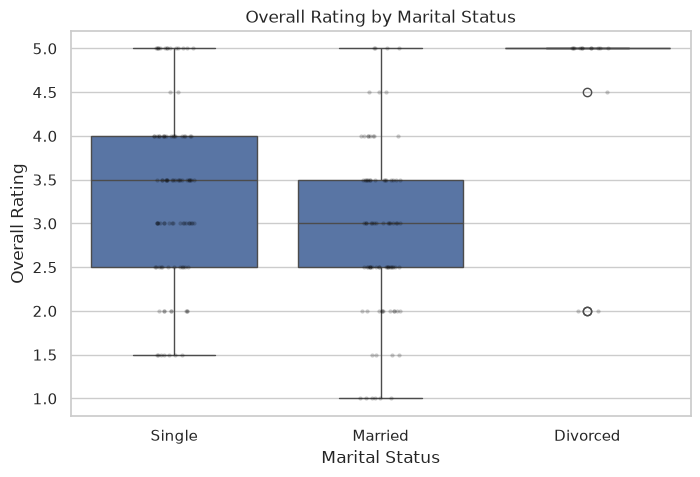

In [36]:
plt.figure(figsize=(8,5))
sns.boxplot(x="Marital Status", y="Overall Rating", data=df)
sns.stripplot(
    x="Marital Status",
    y="Overall Rating",
    data=df,
    color="black",
    alpha=0.2,
    size=3
)
plt.title("Overall Rating by Marital Status")
plt.xlabel("Marital Status")
plt.ylabel("Overall Rating")
plt.show()

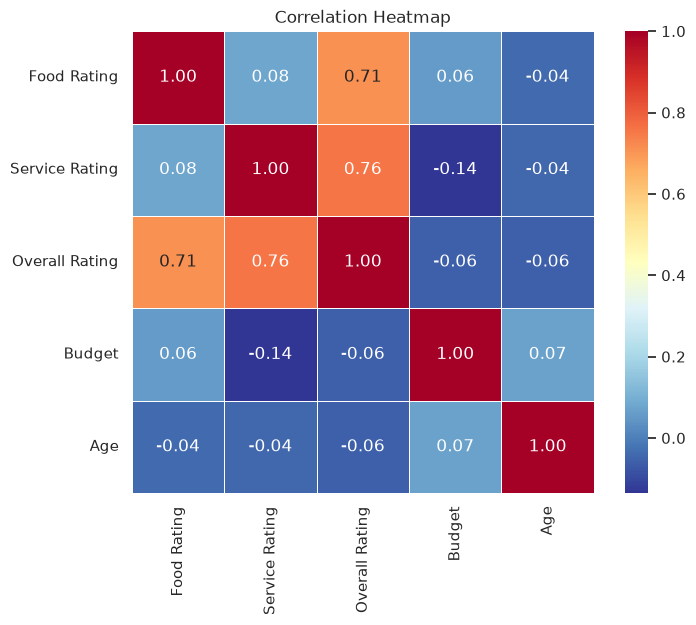

In [37]:
plt.figure(figsize=(8,6))
sns.heatmap(
    df[["Food Rating","Service Rating","Overall Rating","Budget","Age"]].corr(),
    annot=True,
    fmt=".2f",
    cmap="RdYlBu_r",
    linewidths=0.5,
    square=True
)
plt.title("Correlation Heatmap")
plt.show()

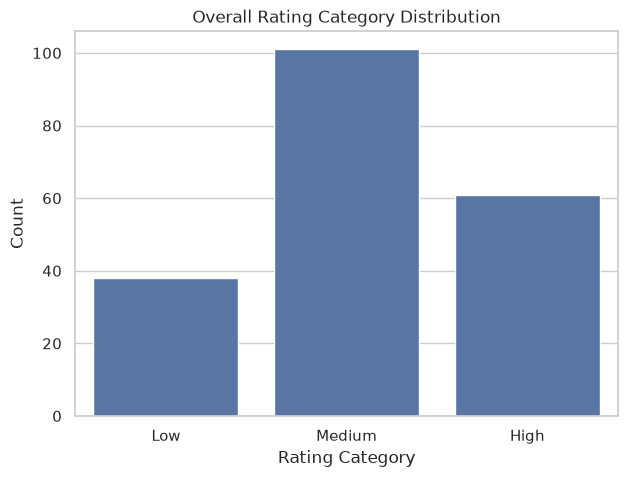

In [40]:
plt.figure(figsize=(7,5))
sns.countplot(x="Rating Category", data=df)
plt.title("Overall Rating Category Distribution")
plt.xlabel("Rating Category")
plt.ylabel("Count")
plt.show()